# 05 · Visor de imágenes

**Objetivo:** ver qué hay en las imágenes antes de decidir índices o modelo:

- compuestos anuales en color real (Landsat y Sentinel-2);
- bandas por sensor y si son consistentes;
- observaciones limpias por píxel, para saber si los compuestos son confiables año por año;
- vista previa de NDVI, EVI y NBR.

**Los índices de esta notebook son solo vista previa.** La decisión se toma después de revisar estas imágenes.

- Solo lee datos y no escribe archivos.
- Las miniaturas se descargan como PNG de vista previa, no como datos de análisis.

**Estado:** notebook nuevo, todavía sin ejecutar.


## 1. Configuración


In [1]:
from datetime import date, datetime
from pathlib import Path
import hashlib
import io
import json
import re

import ee
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

GEE_PROJECT = "viirs-peru"
ANIO_INI, ANIO_FIN = 2010, 2025  # 15 periodos anuales: 2010 -> 2025

# Bandas por sensor: nombre común -> banda original
BANDAS_LANDSAT = {
    "L5": {"blue": "SR_B1", "green": "SR_B2", "red": "SR_B3", "nir": "SR_B4", "swir1": "SR_B5", "swir2": "SR_B7"},
    "L7": {"blue": "SR_B1", "green": "SR_B2", "red": "SR_B3", "nir": "SR_B4", "swir1": "SR_B5", "swir2": "SR_B7"},
    "L8": {"blue": "SR_B2", "green": "SR_B3", "red": "SR_B4", "nir": "SR_B5", "swir1": "SR_B6", "swir2": "SR_B7"},
    "L9": {"blue": "SR_B2", "green": "SR_B3", "red": "SR_B4", "nir": "SR_B5", "swir1": "SR_B6", "swir2": "SR_B7"},
}
BANDAS_S2 = {"blue": "B2", "green": "B3", "red": "B4", "nir": "B8", "swir1": "B11", "swir2": "B12"}
COLECCIONES_LANDSAT = {
    "L5": "LANDSAT/LT05/C02/T1_L2",
    "L7": "LANDSAT/LE07/C02/T1_L2",
    "L8": "LANDSAT/LC08/C02/T1_L2",
    "L9": "LANDSAT/LC09/C02/T1_L2",
}
COLECCION_S2 = "COPERNICUS/S2_SR_HARMONIZED"
MB_ASSET = "projects/mapbiomas-public/assets/peru/collection4/mapbiomas_peru_collection4_coverage_v1"


def buscar_raiz(inicio=None):
    """Sube por las carpetas hasta encontrar la raíz del proyecto (la que tiene el límite provincial).
    Se usa el GeoPackage como marcador porque puede existir una carpeta data/raw dentro de notebooks/."""
    inicio = Path(inicio or Path.cwd()).resolve()
    for carpeta in [inicio, *inicio.parents]:
        if (carpeta / "data" / "raw" / "Provincia" / "PROVINCIA.gpkg").is_file():
            return carpeta
    raise FileNotFoundError("No encuentro data/raw/Provincia/PROVINCIA.gpkg desde esta ubicación.")


def iniciar_gee(proyecto=GEE_PROJECT):
    try:
        ee.Initialize(project=proyecto)
    except Exception:
        ee.Authenticate()
        ee.Initialize(project=proyecto)


def rango_fechas(col):
    """Primera y última fecha de una colección, como texto."""
    d = ee.Dictionary({
        "min": col.aggregate_min("system:time_start"),
        "max": col.aggregate_max("system:time_start"),
    }).getInfo()
    if d["min"] is None:
        return "sin fecha"
    a = pd.to_datetime(d["min"], unit="ms").strftime("%Y-%m-%d")
    b = pd.to_datetime(d["max"], unit="ms").strftime("%Y-%m-%d")
    return f"{a} → {b}"


def md5(ruta):
    """Suma MD5 de un archivo, leído por bloques."""
    h = hashlib.md5()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()


iniciar_gee()
RAIZ = buscar_raiz()
GPKG = RAIZ / "data" / "raw" / "Provincia" / "PROVINCIA.gpkg"
gdf = gpd.read_file(GPKG)
prov = gdf[(gdf["ccdd"] == "08") & (gdf["ccpp"] == "01")]
assert len(prov) == 1, "El filtro de provincia no devolvió exactamente 1 registro"
aoi = ee.Geometry(prov.geometry.iloc[0].simplify(0.0001, preserve_topology=True).__geo_interface__)
print("Provincia:", prov["nombprov"].iloc[0], "| ventana:", ANIO_INI, "-", ANIO_FIN)


*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


Provincia: CUSCO | ventana: 2010 - 2025


## 2. Funciones de estandarización y compuestos anuales

Landsat se escala a reflectancia y se enmascaran nubes, sombras y relleno con `QA_PIXEL`. Sentinel-2 se enmascara con la capa `SCL`. El compuesto anual es la mediana de las imágenes limpias de enero a diciembre.


In [2]:
MASCARA_LANDSAT_BITS = 31  # bits 0 a 4 de QA_PIXEL: relleno, nube dilatada, cirrus, nube y sombra


def landsat_estandar(img, sensor):
    """Escala a reflectancia (0-1), pone nombres comunes y enmascara relleno, nubes y sombras."""
    b = BANDAS_LANDSAT[sensor]
    libre = img.select("QA_PIXEL").bitwiseAnd(MASCARA_LANDSAT_BITS).eq(0)
    sr = img.select(list(b.values())).multiply(0.0000275).add(-0.2)
    return sr.rename(list(b.keys())).updateMask(libre).copyProperties(img, ["system:time_start"])


def s2_estandar(img):
    """Reflectancia (0-1), nombres comunes y máscara con la capa SCL (nube, sombra, cirrus, sin dato).
    La colección HARMONIZED ya unifica el desfase de 1000 del baseline 04.00. Verificar con el mínimo de una banda."""
    scl = img.select("SCL")
    libre = (scl.neq(0).And(scl.neq(1)).And(scl.neq(3))
             .And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10)))
    sr = img.select(list(BANDAS_S2.values())).divide(10000)
    return sr.rename(list(BANDAS_S2.keys())).updateMask(libre).copyProperties(img, ["system:time_start"])


def _conteo_obs(col):
    """Número de observaciones limpias por píxel dentro del año."""
    return col.map(lambda img: img.select("blue").multiply(0).add(1).rename("n_obs")).sum()


def _mapear_sensor(sensor):
    return lambda img: landsat_estandar(img, sensor)


def landsat_anual(anio):
    """Mediana anual (enero a diciembre) de Landsat 5, 7, 8 y 9, con conteo de observaciones limpias."""
    col = None
    for sensor, cid in COLECCIONES_LANDSAT.items():
        parte = (ee.ImageCollection(cid).filterBounds(aoi)
                 .filterDate(f"{anio}-01-01", f"{anio + 1}-01-01")
                 .map(_mapear_sensor(sensor)))
        col = parte if col is None else col.merge(parte)
    return col.median().addBands(_conteo_obs(col)).clip(aoi)


def s2_anual(anio):
    """Mediana anual (enero a diciembre) de Sentinel-2 SR, con conteo de observaciones limpias."""
    col = (ee.ImageCollection(COLECCION_S2).filterBounds(aoi)
           .filterDate(f"{anio}-01-01", f"{anio + 1}-01-01")
           .map(s2_estandar))
    return col.median().addBands(_conteo_obs(col)).clip(aoi)


def indices(img):
    """NDVI, EVI y NBR a partir de bandas estandarizadas (vista previa, sin decidir el índice)."""
    ndvi = img.normalizedDifference(["nir", "red"]).rename("NDVI")
    evi = img.expression(
        "2.5 * (NIR - RED) / (NIR + 6 * RED - 7.5 * BLUE + 1)",
        {"NIR": img.select("nir"), "RED": img.select("red"), "BLUE": img.select("blue")},
    ).rename("EVI")
    nbr = img.normalizedDifference(["nir", "swir2"]).rename("NBR")
    return ndvi.addBands(evi).addBands(nbr)


def miniatura(imagen, vis, dims=700):
    """Descarga una vista previa PNG del área de estudio y la devuelve para matplotlib."""
    url = imagen.getThumbURL({**vis, "region": aoi, "dimensions": dims, "format": "png"})
    resp = requests.get(url, timeout=180)
    resp.raise_for_status()
    return plt.imread(io.BytesIO(resp.content))


## 3. Tabla de bandas por sensor

Compara los nombres comunes con las bandas originales. Sirve para confirmar que las bandas de Landsat y Sentinel-2 corresponden a lo mismo.


In [3]:
print("Landsat (nombre común -> banda original):")
display(pd.DataFrame(BANDAS_LANDSAT).T)
print("Sentinel-2 (nombre común -> banda original):")
display(pd.Series(BANDAS_S2, name="banda").to_frame())


Landsat (nombre común -> banda original):


,blue,green,red,nir,swir1,swir2
L5,SR_B1,SR_B2,SR_B3,SR_B4,SR_B5,SR_B7
L7,SR_B1,SR_B2,SR_B3,SR_B4,SR_B5,SR_B7
L8,SR_B2,SR_B3,SR_B4,SR_B5,SR_B6,SR_B7
L9,SR_B2,SR_B3,SR_B4,SR_B5,SR_B6,SR_B7


Sentinel-2 (nombre común -> banda original):


,banda
blue,B2
green,B3
red,B4
nir,B8
swir1,B11
swir2,B12


## 4. Color real: Landsat por año

Cuatro años de referencia. Permite ver si el color y el contraste cambian de forma que parezca cambio de cobertura cuando en realidad es otro sensor o una nube.


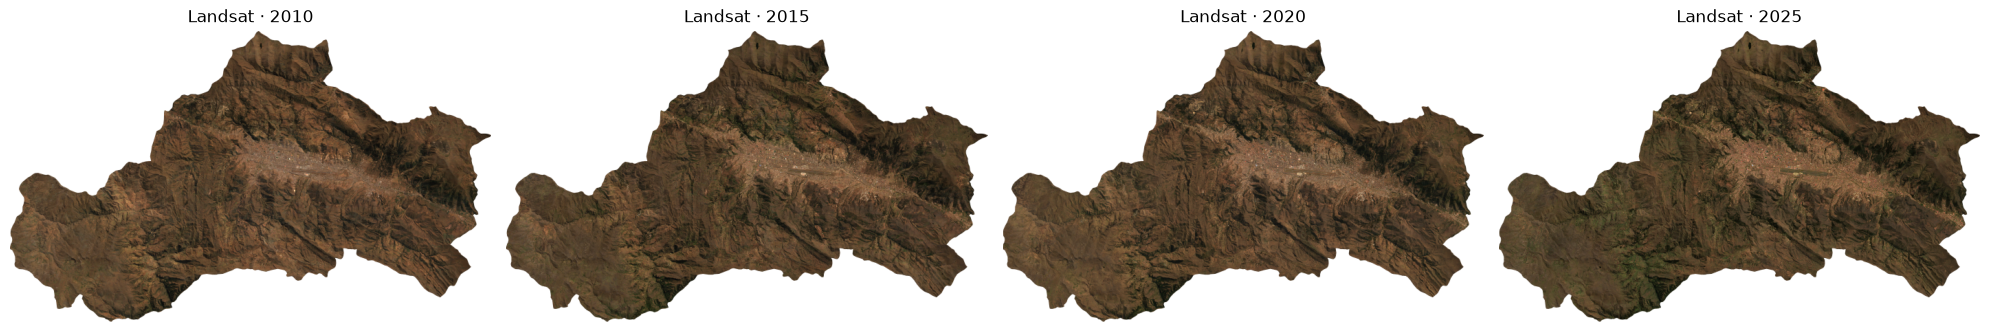

In [4]:
ANIOS_VISTA = [2010, 2015, 2020, 2025]
VIS_COLOR = {"bands": ["red", "green", "blue"], "min": 0.0, "max": 0.3}

fig, ejes = plt.subplots(1, len(ANIOS_VISTA), figsize=(5 * len(ANIOS_VISTA), 5))
for ax, anio in zip(ejes, ANIOS_VISTA):
    ax.imshow(miniatura(landsat_anual(anio), VIS_COLOR))
    ax.set_title(f"Landsat · {anio}")
    ax.axis("off")
plt.tight_layout()
plt.show()


## 5. Landsat frente a Sentinel-2 (año con ambos)

Sirve para ver si Sentinel-2 se parece a Landsat antes de usarlo como complemento.


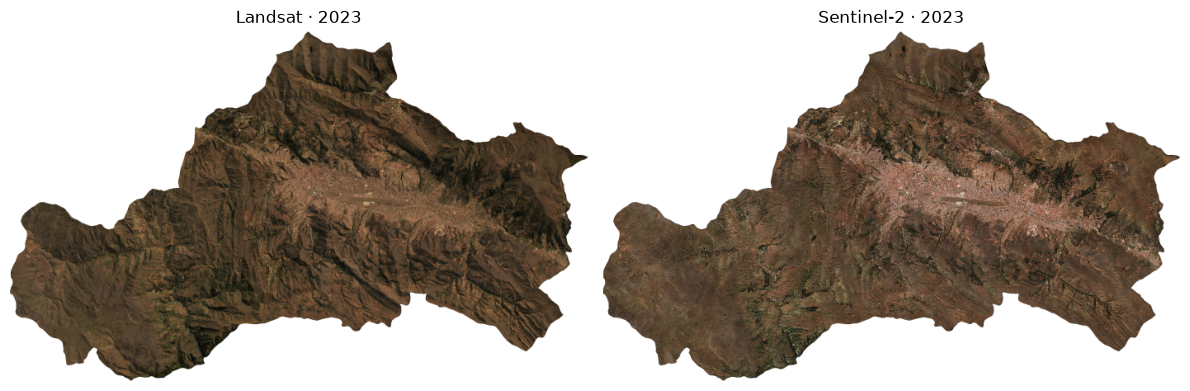

In [5]:
ANIO_COMPARA = 2023
fig, ejes = plt.subplots(1, 2, figsize=(12, 6))
ejes[0].imshow(miniatura(landsat_anual(ANIO_COMPARA), VIS_COLOR))
ejes[0].set_title(f"Landsat · {ANIO_COMPARA}")
ejes[1].imshow(miniatura(s2_anual(ANIO_COMPARA), VIS_COLOR))
ejes[1].set_title(f"Sentinel-2 · {ANIO_COMPARA}")
for ax in ejes:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 6. Vista previa de índices (no es la decisión)

NDVI, EVI y NBR calculados sobre el compuesto de Landsat del año de referencia. Sirven para ver qué resalta cada uno.


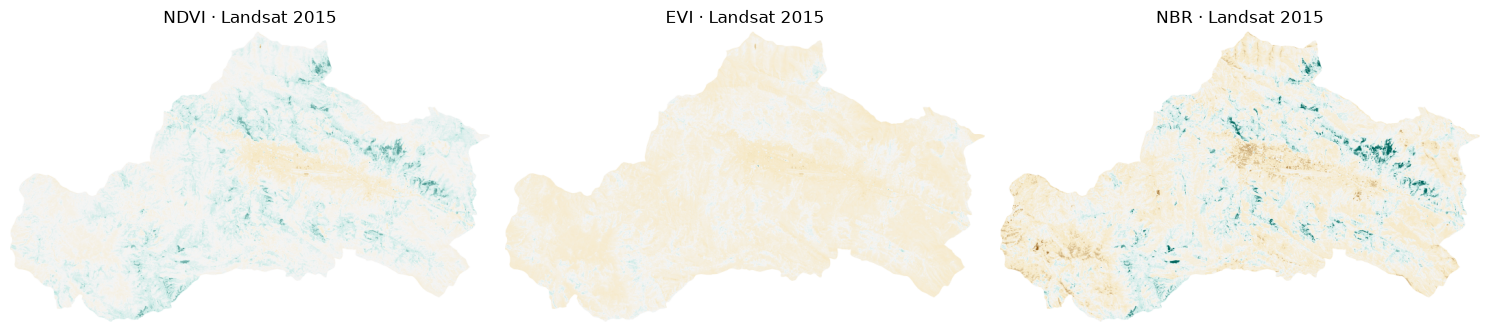

In [6]:
PALETA = ["8c510a", "f6e8c3", "f5f5f5", "c7eae5", "01665e"]
VIS_INDICE = {
    "NDVI": {"min": -0.2, "max": 0.9, "palette": PALETA},
    "EVI": {"min": -0.2, "max": 0.8, "palette": PALETA},
    "NBR": {"min": -0.3, "max": 0.7, "palette": PALETA},
}

img_idx = indices(landsat_anual(ANIOS_VISTA[1]))
fig, ejes = plt.subplots(1, 3, figsize=(15, 5))
for ax, nombre in zip(ejes, ["NDVI", "EVI", "NBR"]):
    ax.imshow(miniatura(img_idx.select(nombre), VIS_INDICE[nombre]))
    ax.set_title(f"{nombre} · Landsat {ANIOS_VISTA[1]}")
    ax.axis("off")
plt.tight_layout()
plt.show()


## 7. Observaciones limpias por píxel

Número de imágenes limpias que tiene cada píxel dentro del año. Si la mediana (valor central) es baja, el compuesto se apoya en pocas observaciones y puede ser menos confiable.

Landsat se revisa en todos los años. Sentinel-2 solo desde 2019, a 10 m.


Landsat (30 m) 2010: calculando...
Landsat (30 m) 2010: listo en 8 s | mediana 13
Landsat (30 m) 2011: calculando...
Landsat (30 m) 2011: listo en 5 s | mediana 14
Landsat (30 m) 2012: calculando...
Landsat (30 m) 2012: listo en 5 s | mediana 6.000000000000001
Landsat (30 m) 2013: calculando...
Landsat (30 m) 2013: listo en 6 s | mediana 12
Landsat (30 m) 2014: calculando...
Landsat (30 m) 2014: listo en 8 s | mediana 17
Landsat (30 m) 2015: calculando...
Landsat (30 m) 2015: listo en 10 s | mediana 16
Landsat (30 m) 2016: calculando...
Landsat (30 m) 2016: listo en 17 s | mediana 17.000000000000004
Landsat (30 m) 2017: calculando...
Landsat (30 m) 2017: listo en 13 s | mediana 16
Landsat (30 m) 2018: calculando...
Landsat (30 m) 2018: listo en 18 s | mediana 16
Landsat (30 m) 2019: calculando...
Landsat (30 m) 2019: listo en 13 s | mediana 19.000000000000014
Landsat (30 m) 2020: calculando...
Landsat (30 m) 2020: listo en 13 s | mediana 20.999999999999982
Landsat (30 m) 2021: calculan

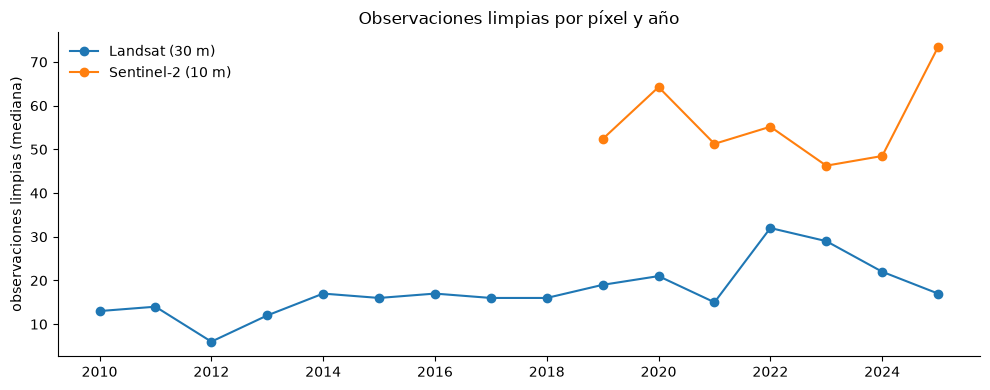

In [7]:
import time


def medir_obs(sensor, anio, fuente_anual, escala):
    """Cuenta observaciones limpias (p5, mediana, p95) de un año y muestra el avance."""
    t0 = time.time()
    print(f"{sensor} {anio}: calculando...", flush=True)
    r = (fuente_anual(anio).select("n_obs")
         .reduceRegion(reducer=ee.Reducer.percentile([5, 50, 95]), geometry=aoi,
                       scale=escala, maxPixels=1e10, bestEffort=True).getInfo())
    print(f"{sensor} {anio}: listo en {time.time() - t0:.0f} s | mediana {r.get('n_obs_p50')}", flush=True)
    return {"año": anio, "sensor": sensor,
            "p5": r.get("n_obs_p5"), "mediana": r.get("n_obs_p50"), "p95": r.get("n_obs_p95")}


inicio_total = time.time()
filas_obs = [medir_obs("Landsat (30 m)", a, landsat_anual, 30)
             for a in range(ANIO_INI, ANIO_FIN + 1)]
filas_obs += [medir_obs("Sentinel-2 (10 m)", a, s2_anual, 10)
              for a in range(2019, ANIO_FIN + 1)]
print(f"Total: {time.time() - inicio_total:.0f} s", flush=True)

tabla_obs = pd.DataFrame(filas_obs)
print(tabla_obs.pivot(index="año", columns="sensor", values="mediana"))

fig, ax = plt.subplots(figsize=(10, 4))
for sensor, grupo in tabla_obs.groupby("sensor"):
    ax.plot(grupo["año"], grupo["mediana"], marker="o", label=sensor)
ax.set_ylabel("observaciones limpias (mediana)")
ax.set_title("Observaciones limpias por píxel y año")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
